In [1]:
import torch
import numpy
from matplotlib import pyplot

import importlib
import velogp
importlib.reload(velogp)

L = 5e6
Growthrate = torch.tensor([1/(20*60)], dtype=torch.double)
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
delay = torch.tensor([360.0, 0.0], dtype=torch.double)
h_tgrid = torch.linspace(0, 0.6*Tr, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velogp.VelocityModel(L, True, origins, ["ori1", "ori2"],
                             h_tgrid, g_xranges_l, g_xranges_u,
                             v0_min=velogp.dtensor([30]), v0_max=velogp.dtensor([30]))
mtrue.growthrate = Growthrate
mtrue.delay = delay
mtrue.v0 = torch.tensor(v0, dtype=torch.double)
mtrue.h_log_raw = torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double))
mtrue.g_delta = torch.tensor([2, 1], dtype=torch.double)

coverage = 1e3
x = torch.linspace(0, L, steps=1000)
y_obs = torch.poisson(mtrue.P(x) * coverage).detach().numpy()
s_obs = numpy.sqrt(y_obs)

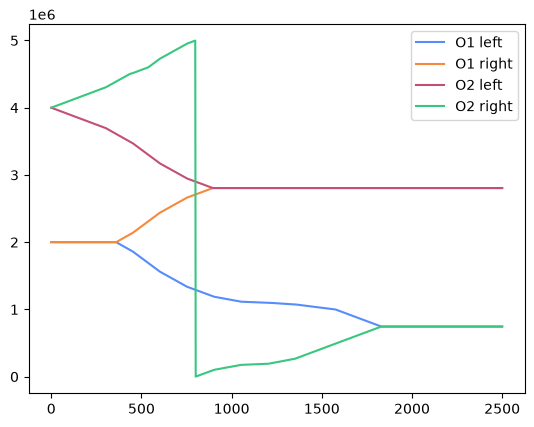

In [2]:
tgrid = torch.linspace(0, Tr, steps=1000, dtype=torch.double)
tab_state, tab_x, tab_y, tab_v = mtrue.trajectories(tgrid)
pyplot.plot(tgrid, tab_x[:, 0], label='O1 left')
pyplot.plot(tgrid, tab_x[:, 1], label='O1 right')
pyplot.plot(tgrid, tab_x[:, 2], label='O2 left')
pyplot.plot(tgrid, tab_x[:, 3], label='O2 right')
pyplot.legend()

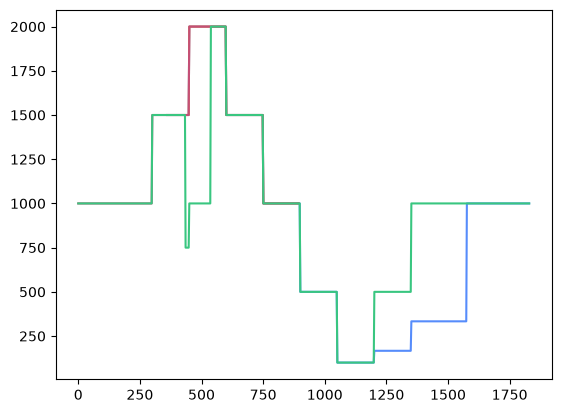

In [3]:
pyplot.plot(tgrid, tab_v[:, 0], label='O1 left')
pyplot.plot(tgrid, tab_v[:, 1], label='O1 right')
pyplot.plot(tgrid, tab_v[:, 2], label='O2 left')
pyplot.plot(tgrid, tab_v[:, 3], label='O2 right')

In [4]:
importlib.reload(velogp)

h_tgrid_dense = torch.linspace(0, Tr, steps=50, dtype=torch.double)
m = velogp.VelocityModel(L, True, origins, ["ori1", "ori2"],
                         h_tgrid_dense, g_xranges_l, g_xranges_u,
                         v0_min=velogp.dtensor([30]), v0_max=velogp.dtensor([3000]))
m.growthrate = Growthrate
m.h_cov_function = "sqexp"
m.g_sigma = torch.tensor([10], dtype=torch.double)
m.h_sigma = torch.tensor([1], dtype=torch.double)
m.h_timescale = torch.tensor([250], dtype=torch.double)
#print(torch.linalg.eigh(m.h_canonical_covariance()))
#print(m.h_eigenvalues())

#torch.autograd.set_detect_anomaly(True)
l = velogp.VelocityModelLoss(x, y_obs=torch.tensor(y_obs), s_obs=torch.tensor(s_obs),
                            model=m, params=["v0_log", "h_log_raw", "g_delta_scaled"])
fit = velogp.FitVelocityModel(m, l)
fit.optimize_parameters(log_steps=True, log_phases=True)
#fit.optimize_parameters_stochastic(steps=100, log_phases=True, log_params=False, log_steps=True)

Determining initial estimates for v0 and delay
Optimizing v0 and g()
  Initially:
      loss: 5.353e+03 = 5.353e+03 * 1.000e+00
  LBFGS Step 1/10, learning rate 0.1
    LBFGS iterations: 10
    After step:
      loss: 3.014e+03 = 5.630e-01 * 5.353e+03
    Final gradients: pos=1, neg=2, zero=0, max=0.02688528398798773, min=-0.9943547523476394, log-avg. magnitude=0.09916610101963151
    Relative improvement 0.4369598457382631
  LBFGS Step 2/10, learning rate 0.2
    LBFGS iterations: 10
    After step:
      loss: 2.399e+03 = 7.958e-01 * 3.014e+03
    Final gradients: pos=1, neg=2, zero=0, max=0.0055861575783340695, min=-0.04225696257093425, log-avg. magnitude=0.015790779302216222
    Relative improvement 0.20415551745274385
  LBFGS Step 3/10, learning rate 0.30000000000000004
    LBFGS iterations: 10
    After step:
      loss: 2.372e+03 = 9.888e-01 * 2.399e+03
    Final gradients: pos=2, neg=1, zero=0, max=0.0013615831148889868, min=-0.000586234121125323, log-avg. magnitude=0.000891999

In [5]:
params = [m.v0_log, m.g_delta_scaled, m.h_log_raw]
print(fit.evaluate_model_for_parameters(params) * fit.loss_prefactor)
print(max(m.pgradient(params)))

tensor(535.0862, dtype=torch.float64, grad_fn=<MulBackward0>)
tensor(0.0037, dtype=torch.float64)


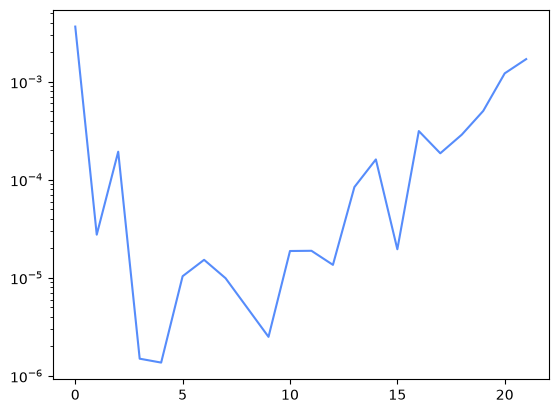

In [6]:
pyplot.plot(abs(m.pgradient(params)))
pyplot.yscale("log")

Text(0, 0.5, 'abundance [reads]')

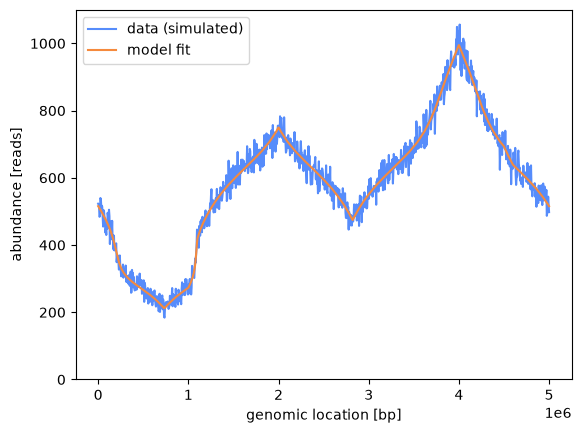

In [7]:
pyplot.plot(fit.loss.x, fit.loss.y_obs.detach(), label="data (simulated)")
pyplot.plot(fit.loss.x, fit.loss.y_pred().detach(), label="model fit")
pyplot.legend()
pyplot.ylim(ymin=0)
pyplot.xlabel("genomic location [bp]")
pyplot.ylabel("abundance [reads]")

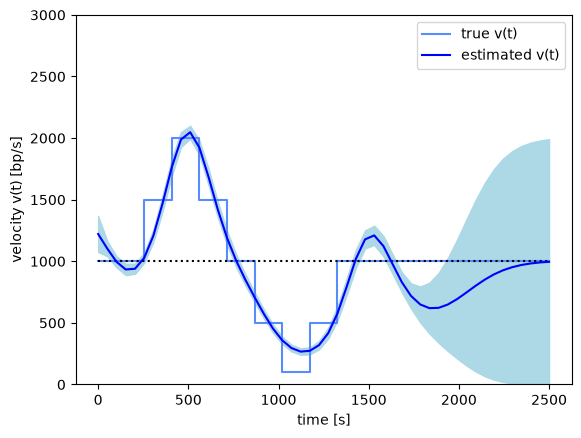

In [8]:
pyplot.step(h_tgrid_dense, mtrue.v_t(h_tgrid_dense).detach(), label="true v(t)")
v_t = m.v_t(fit.model.h_tgrid).detach()
v_t_stderr = m.v_t_posterior_stderr(fit.model.h_tgrid, fit.loss).detach()
pyplot.hlines([m.v0.detach()], xmin=0, xmax=m.h_tgrid.max(),
              linestyle="dotted", color="black")
pyplot.plot(fit.model.h_tgrid, v_t, label="estimated v(t)", color="blue")
pyplot.fill_between(fit.model.h_tgrid,  v_t - v_t_stderr, v_t + v_t_stderr, color="lightblue")
pyplot.xlabel("time [s]")
pyplot.ylabel("velocity v(t) [bp/s]")
pyplot.ylim([0, 3000])
pyplot.legend()